# Task 7: Decision cards

Each card converts a test-set prediction into an operating action. Values come from the newest arrivals only and are compared with a random selection or a dummy model.


In [1]:
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['figure.dpi'] = 110
sns.set_theme(style='whitegrid')

DATA_DIR = Path('../data')
OUTPUT_DIR = Path('../outputs')
SLIDE_DIR = Path('../slides')
MODEL_DIR = Path('../models')
for folder in [DATA_DIR, OUTPUT_DIR, SLIDE_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

from sklearn.metrics import average_precision_score, precision_score, recall_score, mean_absolute_error


In [2]:
metadata = json.loads((OUTPUT_DIR / 'model_metadata.json').read_text(encoding='utf-8'))
cancel = pd.read_csv(OUTPUT_DIR / 'cancellation_test_predictions.csv', parse_dates=['arrival_date'])
adr = pd.read_csv(OUTPUT_DIR / 'adr_test_predictions.csv', parse_dates=['arrival_date'])
results = pd.read_csv(OUTPUT_DIR / 'model_results.csv')

threshold = float(metadata['cancellation_threshold'])
selected = cancel['cancellation_probability'].ge(threshold)
contacted = int(selected.sum())
precision = float(cancel.loc[selected, 'is_canceled'].mean())
recall = float(cancel.loc[selected, 'is_canceled'].sum() / cancel['is_canceled'].sum())
capacity_share = float(selected.mean())
random_recall = capacity_share
lift = recall / random_recall

monthly_cancel_rows = []
cancel_monthly_source = cancel.assign(month=cancel['arrival_date'].dt.to_period('M').astype(str))
for month, group in cancel_monthly_source.groupby('month'):
    monthly_cancel_rows.append({
        'month': month,
        'rows': len(group),
        'pr_auc': average_precision_score(group['is_canceled'], group['cancellation_probability']),
        'precision_at_threshold': precision_score(group['is_canceled'], group['predicted_cancel'], zero_division=0),
        'recall_at_threshold': recall_score(group['is_canceled'], group['predicted_cancel'], zero_division=0),
    })
monthly_cancel = pd.DataFrame(monthly_cancel_rows)

adr_cutoff = 20.0
underpriced = adr['error'].gt(adr_cutoff)
flagged_adr = int(underpriced.sum())
avg_gap = float(adr.loc[underpriced, 'error'].mean()) if flagged_adr else 0.0
total_gap = float(adr.loc[underpriced, 'error'].sum())
best_adr_mae = float(results[
    results['prediction'].eq('ADR') &
    results['split'].eq('Test') &
    results['model'].eq(metadata['selected_adr_model'])
]['mae'].iloc[0])
baseline_adr_mae = float(results[
    results['prediction'].eq('ADR') &
    results['split'].eq('Test') &
    results['model'].eq('Dummy mean')
]['mae'].iloc[0])
mae_improvement = 1 - best_adr_mae / baseline_adr_mae

monthly_adr = adr.assign(month=adr['arrival_date'].dt.to_period('M').astype(str), abs_error=lambda x: x['error'].abs()).groupby('month').agg(rows=('source_row_id','size'), mae=('abs_error','mean'), bias=('error','mean')).reset_index()


## Decision card 1: cancellation risk

The reservations team can review approximately one quarter of new bookings. The threshold comes from the validation period, before test results were inspected.


In [3]:
cancellation_card = {
    '1 Prediction': 'Cancellation risk for each booking when it is created.',
    '2 Metric and why': 'PR-AUC for ranking, with precision and recall at the operating threshold.',
    '3 Cut-off': f"Probability at or above {threshold:.3f}, selected from the validation top quartile.",
    '4 Action': 'Send a confirmation reminder; staff review deposit eligibility before any request.',
    '5 Value': f"Contact {contacted:,} test bookings ({capacity_share:.1%}); {precision:.1%} are cancellations and they capture {recall:.1%} of all cancellations. Random selection at the same volume captures about {random_recall:.1%}; lift is {lift:.2f}x.",
    '6 Model': metadata['selected_cancellation_model'] + ' using booking-time features and training arrivals through 2016.',
    '7 Score': f"Test PR-AUC {average_precision_score(cancel['is_canceled'], cancel['cancellation_probability']):.3f}.",
    '8 Weak spots': 'Monitor recall by hotel, country and guest segment; do not use nationality to set the action.',
    '9 Re-check when': 'Review monthly. Retrain if PR-AUC falls 10% below the validation benchmark for two months.',
    '10 Human check': 'Staff confirm loyalty, company contract and local deposit rules.',
    '11 Finding': 'Long lead time and deposit type carry more risk information than nationality alone.'
}
for k, v in cancellation_card.items(): print(k, '-', v)


1 Prediction - Cancellation risk for each booking when it is created.
2 Metric and why - PR-AUC for ranking, with precision and recall at the operating threshold.
3 Cut-off - Probability at or above 0.609, selected from the validation top quartile.
4 Action - Send a confirmation reminder; staff review deposit eligibility before any request.
5 Value - Contact 10,300 test bookings (25.4%); 79.8% are cancellations and they capture 52.3% of all cancellations. Random selection at the same volume captures about 25.4%; lift is 2.06x.
6 Model - Logistic regression using booking-time features and training arrivals through 2016.
7 Score - Test PR-AUC 0.790.
8 Weak spots - Monitor recall by hotel, country and guest segment; do not use nationality to set the action.
9 Re-check when - Review monthly. Retrain if PR-AUC falls 10% below the validation benchmark for two months.
10 Human check - Staff confirm loyalty, company contract and local deposit rules.
11 Finding - Long lead time and deposit type

## Decision card 2: ADR review

Revenue management reviews quotes more than EUR 20 below the model expectation. The model supports review; it does not automatically change a guest's price.


In [4]:
adr_card = {
    '1 Prediction': 'Expected ADR for each booking when it is created.',
    '2 Metric and why': 'MAE in euros because the error is directly understandable to revenue management.',
    '3 Cut-off': f"Quoted ADR more than EUR {adr_cutoff:.0f} below the model expectation.",
    '4 Action': 'Route the quote to revenue management before confirmation.',
    '5 Value': f"Flag {flagged_adr:,} test bookings. Their average model-to-quote gap is EUR {avg_gap:,.2f}; the gross review opportunity is EUR {total_gap:,.0f}, not guaranteed revenue.",
    '6 Model': metadata['selected_adr_model'] + ' using booking-time features and training arrivals through 2016.',
    '7 Score': f"Test MAE EUR {best_adr_mae:.2f} versus EUR {baseline_adr_mae:.2f} for the mean baseline, an improvement of {mae_improvement:.1%}.",
    '8 Weak spots': 'Monitor MAE and bias by hotel and segment, especially high-price bookings.',
    '9 Re-check when': 'Review monthly. Retrain if MAE rises 20% above the validation benchmark.',
    '10 Human check': 'Confirm package inclusions, room constraints, promotions and contract rates.',
    '11 Finding': 'Season, hotel and requested stay pattern explain a material share of ADR variation.'
}
for k, v in adr_card.items(): print(k, '-', v)


1 Prediction - Expected ADR for each booking when it is created.
2 Metric and why - MAE in euros because the error is directly understandable to revenue management.
3 Cut-off - Quoted ADR more than EUR 20 below the model expectation.
4 Action - Route the quote to revenue management before confirmation.
5 Value - Flag 1,465 test bookings. Their average model-to-quote gap is EUR 40.16; the gross review opportunity is EUR 58,839, not guaranteed revenue.
6 Model - Random forest using booking-time features and training arrivals through 2016.
7 Score - Test MAE EUR 22.47 versus EUR 40.09 for the mean baseline, an improvement of 43.9%.
8 Weak spots - Monitor MAE and bias by hotel and segment, especially high-price bookings.
9 Re-check when - Review monthly. Retrain if MAE rises 20% above the validation benchmark.
10 Human check - Confirm package inclusions, room constraints, promotions and contract rates.
11 Finding - Season, hotel and requested stay pattern explain a material share of ADR va

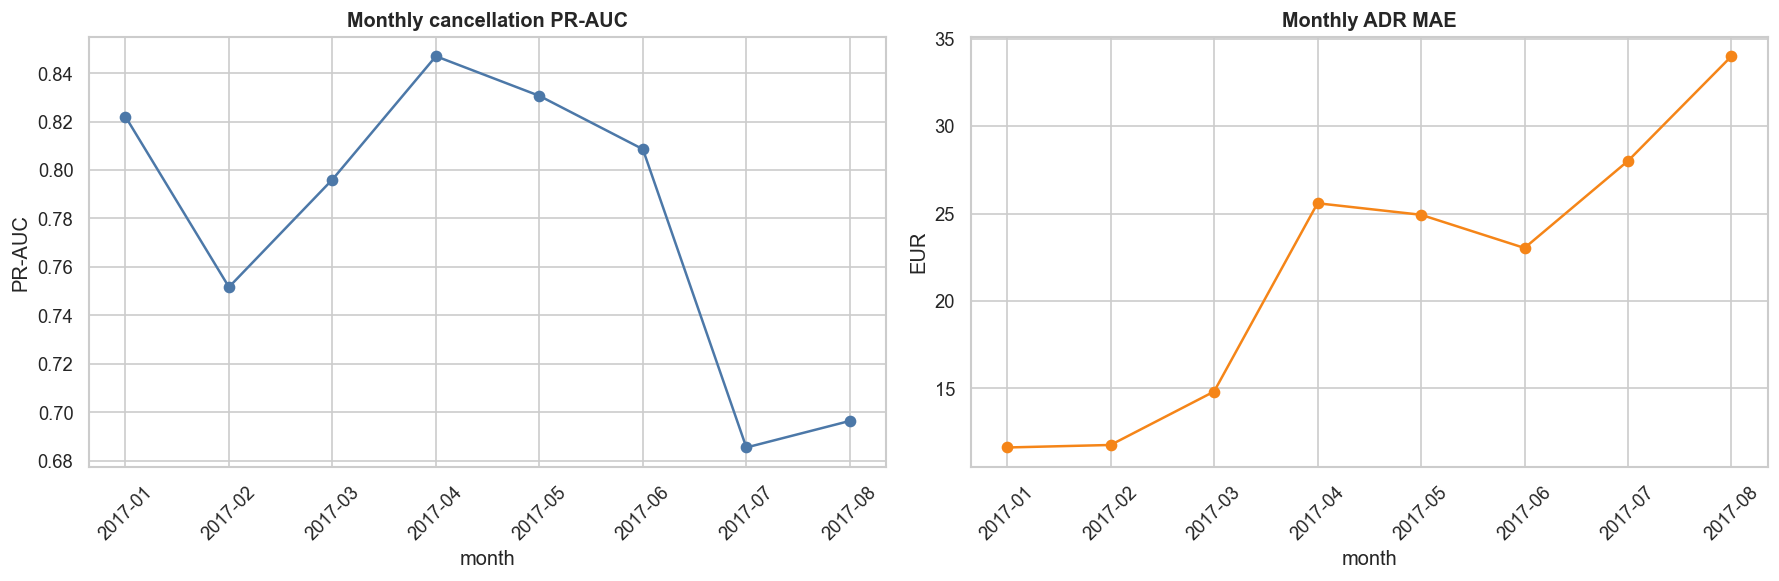

In [5]:
summary = {
    'cancellation': cancellation_card,
    'adr': adr_card,
    'cancellation_monthly': monthly_cancel.to_dict(orient='records'),
    'adr_monthly': monthly_adr.to_dict(orient='records'),
    'metrics': {
        'cancellation_threshold': threshold,
        'contacted': contacted,
        'capacity_share': capacity_share,
        'precision': precision,
        'recall': recall,
        'random_recall': random_recall,
        'lift': lift,
        'adr_cutoff': adr_cutoff,
        'adr_flagged': flagged_adr,
        'adr_avg_gap': avg_gap,
        'adr_total_gap': total_gap,
        'adr_mae': best_adr_mae,
        'adr_baseline_mae': baseline_adr_mae,
        'adr_mae_improvement': mae_improvement,
    }
}
(OUTPUT_DIR / 'decision_cards.json').write_text(json.dumps(summary, indent=2), encoding='utf-8')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
monthly_cancel.plot(x='month', y='pr_auc', marker='o', ax=axes[0], color='#4C78A8', legend=False)
monthly_adr.plot(x='month', y='mae', marker='o', ax=axes[1], color='#F58518', legend=False)
axes[0].set_title('Monthly cancellation PR-AUC', fontweight='bold'); axes[0].set_ylabel('PR-AUC')
axes[1].set_title('Monthly ADR MAE', fontweight='bold'); axes[1].set_ylabel('EUR')
for ax in axes: ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.savefig(SLIDE_DIR / 'decision_monitoring.png', bbox_inches='tight'); plt.show()
